In [5]:
import os

print(os.getcwd())

c:\Users\Shambhavi Singh\OneDrive\Desktop\unified project 1\data cleaning & validation


In [6]:
import pandas as pd

df = pd.read_csv("../data/raw/Nassau Candy Distributor.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [7]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

no missing date values

In [8]:
# Check the data types of the date columns

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    str
Ship Date     str
dtype: object


In [9]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [10]:
# Check the data types of the date columns

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


made both the date columns into same format

In [11]:
df['Ship Date']

0       2026-06-30
1       2026-07-01
2       2026-07-01
3       2026-07-01
4       2026-07-05
           ...    
10189   2030-06-26
10190   2030-06-26
10191   2030-06-26
10192   2030-06-26
10193   2030-06-26
Name: Ship Date, Length: 10194, dtype: datetime64[us]

In [12]:
df['Order Date']

0       2024-01-03
1       2024-01-04
2       2024-01-04
3       2024-01-04
4       2024-01-05
           ...    
10189   2025-12-30
10190   2025-12-30
10191   2025-12-30
10192   2025-12-30
10193   2025-12-30
Name: Order Date, Length: 10194, dtype: datetime64[us]

In [13]:

# Identify records where the ship date is before the order date

invalid_shipments = df[df["Ship Date"] < df["Order Date"]]




In [14]:
print("Total records:", len(df))
print("Ship dates before order dates:", len(invalid_shipments))

# Display invalid records, if any
invalid_shipments[["Order ID", "Order Date", "Ship Date", "Ship Mode"]].head(10)

Total records: 10194
Ship dates before order dates: 0


,Order ID,Order Date,Ship Date,Ship Mode


In [15]:
# Calculate shipping lead time in days

df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Shipping Lead Time"].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64

In [16]:
# Display the 10 records with the longest shipping lead times

df.nlargest(10, "Shipping Lead Time")[
    ["Order ID", "Order Date", "Ship Date", "Ship Mode", "Shipping Lead Time"]
]

,Order ID,Order Date,Ship Date,Ship Mode,Shipping Lead Time
7063,US-2024-136007-CHO-SCR-58000,2025-02-23,2029-08-23,Standard Class,1642
7065,US-2024-136007-CHO-TRI-54000,2025-02-23,2029-08-23,Standard Class,1642
7094,US-2024-111815-CHO-SCR-58000,2025-03-03,2029-08-31,Standard Class,1642
7100,US-2024-111815-CHO-TRI-54000,2025-03-03,2029-08-31,Standard Class,1642
7130,US-2024-104080-CHO-NUT-13000,2025-03-08,2029-09-05,Standard Class,1642
7131,US-2024-104080-CHO-TRI-54000,2025-03-08,2029-09-05,Standard Class,1642
7167,US-2024-105851-CHO-NUT-13000,2025-03-13,2029-09-10,Standard Class,1642
7276,US-2024-113208-CHO-TRI-54000,2025-03-26,2029-09-23,Standard Class,1642
7279,US-2024-162033-CHO-TRI-54000,2025-03-26,2029-09-23,Standard Class,1642
7283,US-2024-162033-CHO-MIL-31000,2025-03-26,2029-09-23,Standard Class,1642


In [17]:
# Compare lead times against shipping modes

df.groupby("Ship Mode")["Shipping Lead Time"].agg(
    ["count", "min", "median", "mean", "max"]
).round(2)

,count,min,median,mean,max
Ship Mode,,,,,
First Class,1548,905,1272.0,1338.28,1638
Same Day,547,904,1269.0,1333.44,1636
Second Class,1979,906,1273.0,1323.85,1640
Standard Class,6120,908,1274.0,1314.33,1642


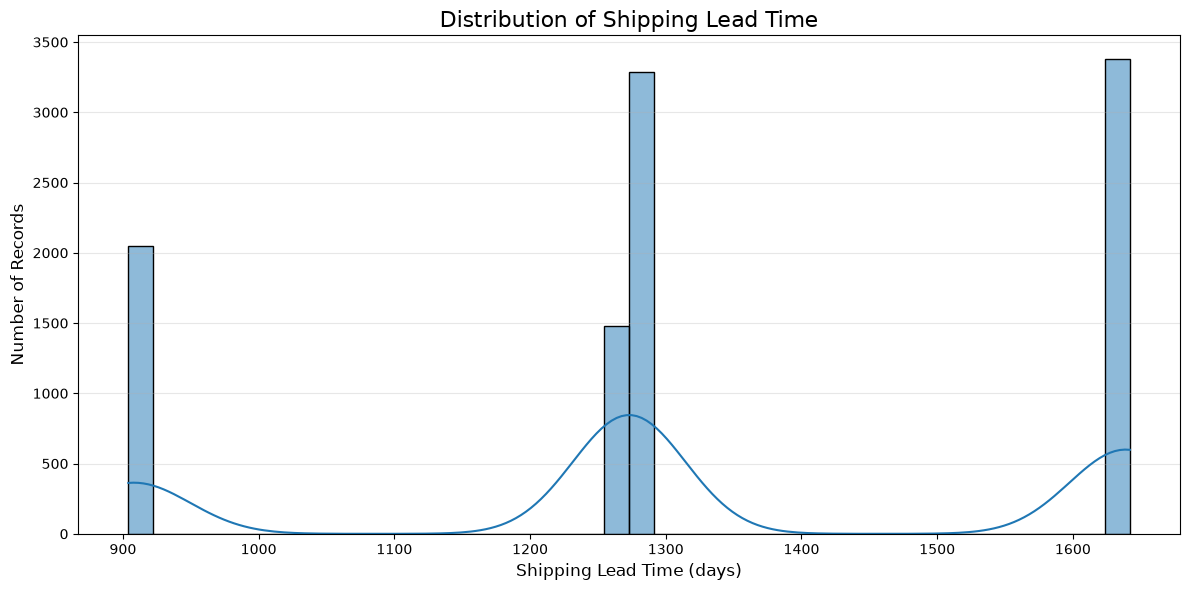

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Shipping Lead Time",
    bins=40,
    kde=True
)

plt.title("Distribution of Shipping Lead Time", fontsize=16)
plt.xlabel("Shipping Lead Time (days)", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


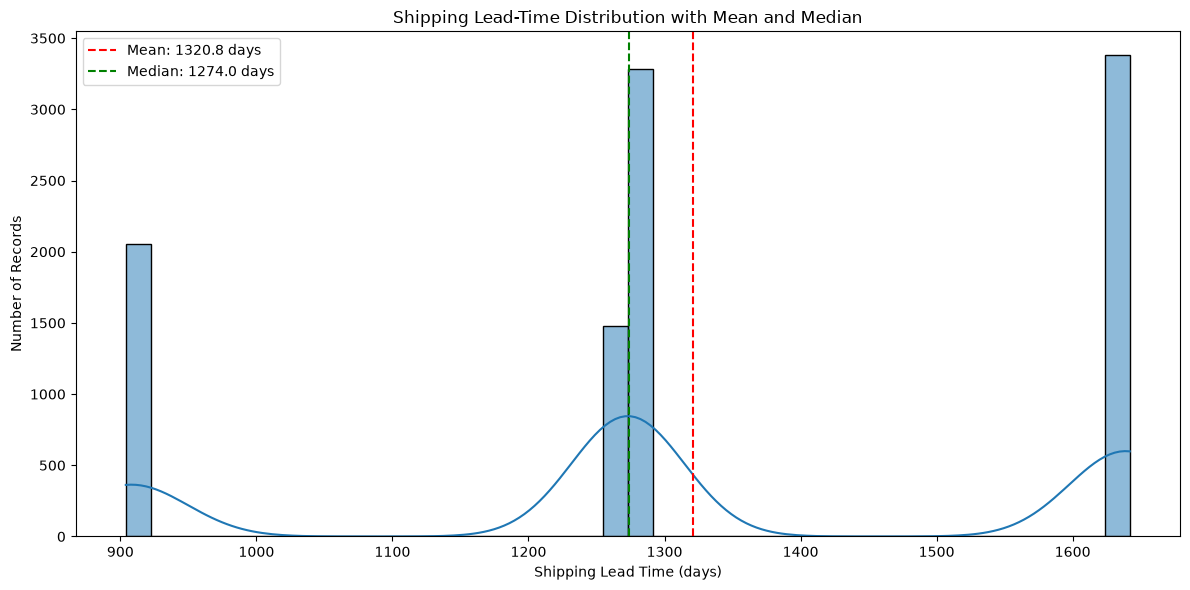

In [19]:

mean_lead_time = df["Shipping Lead Time"].mean()
median_lead_time = df["Shipping Lead Time"].median()

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Shipping Lead Time",
    bins=40,
    kde=True
)

plt.axvline(
    mean_lead_time,
    color="red",
    linestyle="--",
    label=f"Mean: {mean_lead_time:.1f} days"
)

plt.axvline(
    median_lead_time,
    color="green",
    linestyle="--",
    label=f"Median: {median_lead_time:.1f} days"
)

plt.title("Shipping Lead-Time Distribution with Mean and Median")
plt.xlabel("Shipping Lead Time (days)")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
# Diagnostic: why are lead times 900-1,640 days?

df["Order ID Year"] = df["Order ID"].str.extract(r"^US-(\d{4})-")[0].astype("Int64")
df["Order Year"] = df["Order Date"].dt.year
df["Ship Year"] = df["Ship Date"].dt.year

print("Order Date range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Ship Date range :", df["Ship Date"].min(), "to", df["Ship Date"].max())
print("Unparseable (NaT) dates:", df[["Order Date", "Ship Date"]].isna().sum().to_dict())
print("Distinct lead-time values:", df["Shipping Lead Time"].nunique())

print("\nOrder ID year vs Order Date year:")
print(pd.crosstab(df["Order ID Year"], df["Order Year"]))

print("\nOrder Date year vs Ship Date year:")
print(pd.crosstab(df["Order Year"], df["Ship Year"]))

print("\nLead time by order year:")
print(df.groupby("Order Year")["Shipping Lead Time"].describe().round(1))

print("\nLead time value counts (top 15):")
print(df["Shipping Lead Time"].value_counts().head(15))

Order Date range: 2024-01-02 00:00:00 to 2025-12-31 00:00:00
Ship Date range : 2026-06-30 00:00:00 to 2030-06-28 00:00:00
Unparseable (NaT) dates: {'Order Date': 0, 'Ship Date': 0}
Distinct lead-time values: 28

Order ID year vs Order Date year:
Order Year     2024  2025
Order ID Year            
2021           1993     0
2022           2102     0
2023              0  2587
2024              0  3312

Order Date year vs Ship Date year:
Ship Year   2026  2027  2028  2029  2030
Order Year                              
2024         711  2089  1381     0     0
2025           0     0   986  2899  2128

Lead time by order year:
             count    mean    std     min     25%     50%     75%     max
Order Year                                                               
2024        4181.0  1094.0  182.5   904.0   908.0  1269.0  1273.0  1277.0
2025        6013.0  1478.6  181.6  1269.0  1273.0  1637.0  1639.0  1642.0

Lead time value counts (top 15):
Shipping Lead Time
1273    1326
1274    10

In [21]:
# Diagnostic 2: structure of the lead-time clusters

bins = [0, 1000, 1450, 2000]
labels = ["A (~905)", "B (~1270)", "C (~1640)"]
df["LT Cluster"] = pd.cut(df["Shipping Lead Time"], bins=bins, labels=labels)

print("All distinct lead-time values:")
print(df["Shipping Lead Time"].value_counts().sort_index().to_string())

print("\nCluster vs Order Year:")
print(pd.crosstab(df["LT Cluster"], df["Order Year"]))

print("\nCluster vs Ship Mode:")
print(pd.crosstab(df["LT Cluster"], ["Ship Mode"] and df["Ship Mode"]))

print("\nCluster vs Order Quarter:")
print(pd.crosstab(df["Order Date"].dt.to_period("Q"), df["LT Cluster"]))

# Within-cluster offset: lead time minus the cluster's own minimum
df["Cluster Min"] = df.groupby("LT Cluster", observed=True)["Shipping Lead Time"].transform("min")
df["Residual Days"] = df["Shipping Lead Time"] - df["Cluster Min"]

print("\nWithin-cluster residual by Ship Mode:")
print(df.groupby("Ship Mode")["Residual Days"].describe().round(2))

All distinct lead-time values:
Shipping Lead Time
904       89
905       40
906      289
907      176
908      591
909      519
910      207
911      134
912        4
915        2
1269     258
1270     156
1271     610
1272     456
1273    1326
1274    1035
1275     612
1276     293
1277      18
1634       3
1635     179
1636     190
1637     449
1638     411
1639     896
1640     657
1641     397
1642     197

Cluster vs Order Year:
Order Year  2024  2025
LT Cluster            
A (~905)    2051     0
B (~1270)   2130  2634
C (~1640)      0  3379

Cluster vs Ship Mode:
Ship Mode   First Class  Same Day  Second Class  Standard Class
LT Cluster                                                     
A (~905)            293        92           388            1278
B (~1270)           679       267           925            2893
C (~1640)           576       188           666            1949

Cluster vs Order Quarter:
LT Cluster  A (~905)  B (~1270)  C (~1640)
Order Date                        

In [22]:
# Diagnostic 3: test the "base offset + 365*k + small real gap" hypothesis

BASE = 904  # smallest observed gap; an observation, not a verified business rule
lt = df["Shipping Lead Time"]

df["Offset Step k"] = 0
df.loc[lt >= BASE + 365, "Offset Step k"] = 1
df.loc[lt >= BASE + 730, "Offset Step k"] = 2

df["Candidate Ship Days (hypothesis)"] = lt - BASE - 365 * df["Offset Step k"]

print("Candidate gap distribution:")
print(df["Candidate Ship Days (hypothesis)"].describe().round(2))
print("Any negative?", (df["Candidate Ship Days (hypothesis)"] < 0).any())

print("\nWhat decides k? Step vs order year:")
print(pd.crosstab(df["Order Year"], df["Offset Step k"]))

print("\nStep vs order quarter:")
print(pd.crosstab(df["Order Date"].dt.to_period("Q"), df["Offset Step k"]))

print("\nStep vs Order ID year:")
print(pd.crosstab(df["Order ID Year"], df["Offset Step k"]))

print("\nStep vs Region:")
print(pd.crosstab(df["Region"], df["Offset Step k"]))

print("\nCandidate days by ship mode and step (mean):")
print(df.pivot_table(index="Ship Mode", columns="Offset Step k",
                     values="Candidate Ship Days (hypothesis)", aggfunc="mean").round(2))

Candidate gap distribution:
count    10194.00
mean         4.29
std          1.80
min          0.00
25%          3.00
50%          4.00
75%          5.00
max         11.00
Name: Candidate Ship Days (hypothesis), dtype: float64
Any negative? False

What decides k? Step vs order year:
Offset Step k     0     1     2
Order Year                     
2024           2051  2130     0
2025              0  2634  3379

Step vs order quarter:
Offset Step k    0    1     2
Order Date                   
2024Q1         289  269     0
2024Q2         403  448     0
2024Q3         574  597     0
2024Q4         785  816     0
2025Q1           0  344   513
2025Q2           0  605   697
2025Q3           0  750   918
2025Q4           0  935  1251

Step vs Order ID year:
Offset Step k     0     1     2
Order ID Year                  
2021           1993     0     0
2022              0  2102     0
2023              0  2587     0
2024              0     0  3312

Step vs Region:
Offset Step k    0     1     2


In [23]:
df["Order ID Year"] = df["Order ID"].str.extract(r"^[A-Z]{2}-(\d{4})-")[0].astype(int)
df["Order Key"] = df["Order ID"].str.extract(r"^([A-Z]{2}-\d{4}-\d+)-")[0]
df["Is Canada"] = df["Country/Region"].eq("Canada")

# HYPOTHESIS, fitted to this data (not a verified business rule)
YEAR_SHIFT = {2021: 2, 2022: 3, 2023: 3, 2024: 4}

shifted_ship = pd.Series(
    [s - pd.DateOffset(years=YEAR_SHIFT[y]) for s, y in zip(df["Ship Date"], df["Order ID Year"])],
    index=df.index,
)
df["Gap After Year Shift (days)"] = (shifted_ship - df["Order Date"]).dt.days

print("Gap after whole-year shift:")
print(df["Gap After Year Shift (days)"].describe().round(2))

print("\nBy ship mode (mean / min / max):")
print(df.groupby("Ship Mode")["Gap After Year Shift (days)"].agg(["mean", "min", "max"]).round(2))

print("\nOrder ID year vs Order Date year (all 10,194 rows):")
print(pd.crosstab(df["Order ID Year"], df["Order Date"].dt.year, margins=True))

print("\nOrders with more than one Ship Date:",
      int((df.groupby("Order Key")["Ship Date"].nunique() > 1).sum()))
print("Distinct orders:", df["Order Key"].nunique(), "| Canadian rows:", int(df["Is Canada"].sum()))

Gap after whole-year shift:
count    10194.00
mean       177.59
std          1.82
min        173.00
25%        176.00
50%        178.00
75%        179.00
max        185.00
Name: Gap After Year Shift (days), dtype: float64

By ship mode (mean / min / max):
                  mean  min  max
Ship Mode                       
First Class     175.84  174  179
Same Day        173.63  173  175
Second Class    176.86  175  180
Standard Class  178.63  176  185

Order ID year vs Order Date year (all 10,194 rows):
Order Date     2024  2025    All
Order ID Year                   
2021           2051     0   2051
2022           2130     0   2130
2023              0  2634   2634
2024              0  3379   3379
All            4181  6013  10194

Orders with more than one Ship Date: 0
Distinct orders: 5111 | Canadian rows: 200


### Result: year-shift idea

- After moving Ship Date back by whole years (2, 3, 3, 4 years for Order ID years 2021 to 2024), the gap is **173 to 185 days** (before: 904 to 1,642).
- The spread is small (std about 1.8 days) and sorted by ship mode: Same Day (about 173.6), First Class (about 175.8), Second Class (about 176.9), Standard (about 178.6).
- All 5,111 orders have exactly one Ship Date each.
- All 10,194 rows are included (9,994 US, 200 Canada).

**What this means:** The idea fits the data well. A constant base of about 173 days remains, so exact days are not real shipping time. Only differences between modes and routes can be compared.

**Status:** Hypothesis only. Needs confirmation from the data owner.

In [25]:
import numpy as np

ORIGINAL_COLS = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode", "Customer ID",
                 "Country/Region", "City", "State/Province", "Postal Code", "Division", "Region",
                 "Product ID", "Product Name", "Sales", "Units", "Gross Profit", "Cost"]

# 1. Hidden blanks in text columns (nulls were already 0)
text_cols = df[ORIGINAL_COLS].select_dtypes(include=["object", "string"]).columns
PLACEHOLDERS = {"", "na", "n/a", "null", "none", "unknown", "-"}
hidden = {c: int(df[c].astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()) for c in text_cols}
print("Hidden blanks:", {k: v for k, v in hidden.items() if v > 0} or "none")

# 2. Duplicates, three definitions
same_except_id = df[ORIGINAL_COLS].drop(columns=["Row ID"]).duplicated()
print("\nDuplicate Row IDs:", df["Row ID"].duplicated().sum())
print("Rows identical except Row ID:", same_except_id.sum())
print("Repeated (Order ID, Product ID) pairs:", df.duplicated(subset=["Order ID", "Product ID"]).sum())

print("\nSample of identical rows:")
print(df[df[ORIGINAL_COLS].drop(columns=["Row ID"]).duplicated(keep=False)]
      .sort_values(["Order ID", "Product ID"])
      [["Row ID", "Order ID", "Product ID", "Sales", "Units"]].head(10).to_string(index=False))

# 3. Number checks
print("\nSales <= 0:", int((df["Sales"] <= 0).sum()), "| Units <= 0:", int((df["Units"] <= 0).sum()))
mismatch = ~np.isclose(df["Sales"] - df["Cost"], df["Gross Profit"], atol=0.02)
print("Rows where Sales - Cost != Gross Profit:", int(mismatch.sum()))
print("\nNumbers summary:")
print(df[["Sales", "Units", "Gross Profit", "Cost"]].describe().round(2))

Hidden blanks: none

Duplicate Row IDs: 0
Rows identical except Row ID: 313
Repeated (Order ID, Product ID) pairs: 1645

Sample of identical rows:
 Row ID                     Order ID    Product ID  Sales  Units
   2020 CA-2021-123625-CHO-MIL-31000 CHO-MIL-31000   6.50      2
   2021 CA-2021-123625-CHO-MIL-31000 CHO-MIL-31000   6.50      2
   1870 CA-2021-151799-CHO-MIL-31000 CHO-MIL-31000   6.50      2
   1874 CA-2021-151799-CHO-MIL-31000 CHO-MIL-31000   6.50      2
   1699 CA-2021-153623-CHO-SCR-58000 CHO-SCR-58000  28.80      8
   1700 CA-2021-153623-CHO-SCR-58000 CHO-SCR-58000  28.80      8
   2510 CA-2022-132548-CHO-MIL-31000 CHO-MIL-31000  16.25      5
   2513 CA-2022-132548-CHO-MIL-31000 CHO-MIL-31000  16.25      5
   4008 CA-2022-155586-CHO-SCR-58000 CHO-SCR-58000  14.40      4
   4009 CA-2022-155586-CHO-SCR-58000 CHO-SCR-58000  14.40      4

Sales <= 0: 0 | Units <= 0: 0
Rows where Sales - Cost != Gross Profit: 0

Numbers summary:
          Sales     Units  Gross Profit      C

### Result: data quality checks

- No hidden blanks. No duplicate Row IDs. No Sales or Units at or below zero.
- Sales - Cost = Gross Profit on every row, so Cost is product cost, not shipping cost. No cost-vs-time analysis is possible.
- 313 rows are identical except Row ID (same product repeated within an order).

**Decision:** Keep all rows and flag repeats. Count shipments as distinct orders (5,111), not rows (10,194).

In [26]:
geo_cols = ["Country/Region", "City", "State/Province", "Region", "Postal Code"]

# 1. Extra spaces
for c in geo_cols:
    s = df[c].astype(str)
    n_space = (s != s.str.strip().str.replace(r"\s+", " ", regex=True)).sum()
    print(f"{c}: {df[c].nunique()} unique values, {n_space} with extra spaces")

# 2. Same name spelled in more than one way
for c in ["Country/Region", "State/Province", "City", "Region"]:
    sp = df.groupby(df[c].astype(str).str.strip().str.lower())[c].nunique()
    print(f"{c} spelled in more than one way:", list(sp[sp > 1].index) or "none")

# 3. Postal codes (4-digit codes would mean leading zeros were lost)
pc = df["Postal Code"].astype(str)
print("\nPostal code lengths:", pc.str.len().value_counts().to_dict())
print("Non-numeric postal codes by country:", df.loc[~pc.str.fullmatch(r"\d+"), "Country/Region"].value_counts().to_dict())

# 4. States and regions
state_region = df.groupby("State/Province")["Region"].nunique()
print("\nStates in more than one region:", list(state_region[state_region > 1].index) or "none")
print(df.groupby("Region")["State/Province"].nunique())
print("Canada provinces:", sorted(df.loc[df["Is Canada"], "State/Province"].unique()))
print("Canada rows by region:", df.loc[df["Is Canada"], "Region"].value_counts().to_dict())
print("US state/province values:", df.loc[~df["Is Canada"], "State/Province"].nunique())

# 5. Products (needed for the factory join)
prod = df.groupby("Product ID")[["Product Name", "Division"]].nunique()
print("\nProduct IDs with more than one name or division:", int((prod > 1).any(axis=1).sum()))
print(df[["Product ID", "Product Name", "Division"]].drop_duplicates().sort_values("Product ID").to_string(index=False))

Country/Region: 2 unique values, 0 with extra spaces
City: 542 unique values, 0 with extra spaces
State/Province: 59 unique values, 0 with extra spaces
Region: 4 unique values, 0 with extra spaces
Postal Code: 654 unique values, 0 with extra spaces
Country/Region spelled in more than one way: none
State/Province spelled in more than one way: none
City spelled in more than one way: none
Region spelled in more than one way: none

Postal code lengths: {5: 9545, 4: 449, 3: 200}
Non-numeric postal codes by country: {'Canada': 200}

States in more than one region: none
Region
Atlantic    20
Gulf        11
Interior    14
Pacific     14
Name: State/Province, dtype: int64
Canada provinces: ['Alberta', 'British Columbia', 'Manitoba', 'New Brunswick', 'Newfoundland and Labrador', 'Nova Scotia', 'Ontario', 'Prince Edward Island', 'Quebec', 'Saskatchewan']
Canada rows by region: {'Atlantic': 138, 'Pacific': 50, 'Interior': 12}
US state/province values: 49

Product IDs with more than one name or div

In [27]:
# 1. Which states have 4-digit postal codes?
pc = df["Postal Code"].astype(str)
four = df[(pc.str.len() == 4) & ~df["Is Canada"]]
print("4-digit US postal codes by state:")
print(four["State/Province"].value_counts())
print("Examples:", four["Postal Code"].astype(str).unique()[:10])

# 2. All 15 products with counts
products = (df.groupby(["Product ID", "Product Name", "Division"])
              .agg(rows=("Row ID", "count"), orders=("Order Key", "nunique"))
              .reset_index())
print()
print(products.to_string(index=False))

4-digit US postal codes by state:
State/Province
Massachusetts    135
New Jersey       130
Connecticut       82
Rhode Island      56
New Hampshire     27
Vermont           11
Maine              8
Name: count, dtype: int64
Examples: <ArrowStringArray>
['7036', '2151', '6457', '1841', '2038', '3820', '8701', '6450', '7060',
 '7601']
Length: 10, dtype: str

   Product ID                      Product Name  Division  rows  orders
CHO-FUD-51000         Wonka Bar - Fudge Mallows Chocolate  1818    1527
CHO-MIL-31000        Wonka Bar - Milk Chocolate Chocolate  2137    1768
CHO-NUT-13000 Wonka Bar - Nutty Crunch Surprise Chocolate  1810    1529
CHO-SCR-58000    Wonka Bar -Scrumdiddlyumptious Chocolate  2064    1704
CHO-TRI-54000 Wonka Bar - Triple Dazzle Caramel Chocolate  2015    1677
OTH-FIZ-56000              Fizzy Lifting Drinks     Sugar     6       6
OTH-GUM-21000                         Wonka Gum     Other   120     118
OTH-KAZ-38000                         Kazookles     Other    96    

### Result: postal codes and products

- 449 US postal codes had 4 digits, all in New England and New Jersey: the leading zero was lost. Fix: pad US codes to 5 digits.
- 15 products. 5 chocolate bars cover about 97% of rows. The other 10 products have very few orders.
- `OTH-FIZ-56000` has an OTH ID but sits in the Sugar division (to be checked).

In [28]:
# 1. Fix US postal codes (Canada left as is)
us = ~df["Is Canada"]
df["Postal Code"] = df["Postal Code"].astype(str)
df.loc[us, "Postal Code"] = df.loc[us, "Postal Code"].str.zfill(5)
assert df.loc[us, "Postal Code"].str.len().eq(5).all()
print("US postal code lengths:", df.loc[us, "Postal Code"].str.len().value_counts().to_dict())
print("Massachusetts examples:", df.loc[us & (df["State/Province"] == "Massachusetts"), "Postal Code"].head(3).tolist())

# 2. Flag repeated lines (kept, not removed)
df["Is Repeated Line"] = df[ORIGINAL_COLS].drop(columns=["Row ID"]).duplicated()
print("\nRepeated lines flagged:", int(df["Is Repeated Line"].sum()))

# 3. Does the Product ID prefix match the Division?
df["ID Prefix"] = df["Product ID"].str.split("-").str[0]
print()
print(pd.crosstab(df["ID Prefix"], df["Division"]))

# 4. Save the validated data (raw file is not touched)
OUT = "../data/processed/orders_validated.csv"
df.to_csv(OUT, index=False)
print("\nSaved:", OUT, "| rows:", len(df))

US postal code lengths: {5: 9994}
Massachusetts examples: ['02151', '02151', '01841']

Repeated lines flagged: 313

Division   Chocolate  Other  Sugar
ID Prefix                         
CHO             9844      0      0
OTH                0    310      6
SUG                0      0     34

Saved: ../data/processed/orders_validated.csv | rows: 10194


### Result: fixes applied and file saved

- US postal codes padded to 5 digits (9,994 rows OK). Canada left as is.
- 313 repeated lines flagged, not removed.
- Only mismatch between Product ID prefix and Division: 6 rows of `OTH-FIZ-56000` (Sugar). Kept as given.
- Validated data saved to `data/processed/orders_validated.csv` (10,194 rows).

In [29]:
print((df.groupby("Customer ID")["State/Province"].nunique() > 1).sum(), "customers with more than one state")

28 customers with more than one state


In [30]:
print(df["Customer ID"].nunique(), "customers |", df["Order Key"].nunique(), "orders |", len(df), "rows")

5044 customers | 5111 orders | 10194 rows


In [31]:
rows_per_order = df.groupby("Order Key").size()
print(rows_per_order.value_counts().sort_index())
print("average rows per order:", round(rows_per_order.mean(), 2))

1     2593
2     1242
3      612
4      344
5      164
6       72
7       51
8       16
9       10
10       3
11       2
12       1
14       1
Name: count, dtype: int64
average rows per order: 1.99
